# EDA - Folin Fos Timor-Leste
**Exploratory Data Analysis** · Capstone Project *Mining and Exploring* · Dili Institute of Technology (DIT)

Rice only: **Fos Lokal** (WFP "Rice (white, local)") and **Fos Importadu** (WFP "Rice (white, imported)"),
retail prices in USD/kg, averaged per municipality (district). Source: WFP Food Prices Timor-Leste (HDX),
plus daily Taibesi prices from the Google Sheet when available.

Dadus / data: `data/processed/agri_prices_clean.csv` (run `src/collect.py` and `src/preprocessing.py` first).

Contents: 1. Load data · 2. Descriptive statistics · 3. Trend · 4. Distribution by district · 5. Dili vs other districts · 6. Correlation local vs imported · 7. Seasonality · 8. Insights

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Interactive charts in Jupyter + a static PNG copy (so the charts also show on GitHub)
try:
    px.line(x=[0, 1], y=[0, 1]).to_image(format="png")
    pio.renderers.default = "notebook_connected+png"
    PNG = True
except Exception:
    pio.renderers.default = "notebook_connected"
    PNG = False

COR = {"Fos Lokal": "#3478A6", "Fos Importadu": "#D99412"}

def save(fig, name, height=500):
    """Save every EDA chart for the report (HTML always, PNG if kaleido works)."""
    fig.update_layout(template="plotly_white")
    fig.write_html(FIG / f"{name}.html", include_plotlyjs="cdn")
    if PNG:
        fig.write_image(FIG / f"{name}.png", width=1000, height=height, scale=2)
    return fig

## 1. Load data / Karrega dadus

In [2]:
df = pd.read_csv(ROOT / "data/processed/agri_prices_clean.csv", parse_dates=["data"])
print(df.shape)
print("Atualizadu (last collection, UTC):", df["timestamp"].max())
df.head()

(1574, 18)
Atualizadu (last collection, UTC): 2026-09-28T19:04:39Z


,data,produto,folin_kg_usd,lokalizasaun,timestamp,source_url,fonte,n_merkadu,folin_imputadu,folin_kotuk,folin_media_7_dias,folin_7_loron_kotuk,frekuensia,tinan,fulan,dia_semana,dia_semana_naran,is_dili
0,2020-05-15,Fos Importadu,0.53,Aileu,2026-09-28T19:04:39Z,https://data.humdata.org/dataset/wfp-food-pric...,WFP/HDX,1,False,NaN,NaN,NaN,fulan,2020,5,4,Sesta,0
1,2020-06-15,Fos Importadu,0.52,Aileu,2026-09-28T19:04:39Z,https://data.humdata.org/dataset/wfp-food-pric...,WFP/HDX,1,False,0.53,0.5300,0.53,fulan,2020,6,0,Segunda,0
2,2020-07-15,Fos Importadu,0.52,Aileu,2026-09-28T19:04:39Z,https://data.humdata.org/dataset/wfp-food-pric...,WFP/HDX,1,False,0.52,0.5250,0.52,fulan,2020,7,2,Kuarta,0
3,2020-08-15,Fos Importadu,0.53,Aileu,2026-09-28T19:04:39Z,https://data.humdata.org/dataset/wfp-food-pric...,WFP/HDX,1,False,0.52,0.5233,0.52,fulan,2020,8,5,Sábadu,0
4,2020-09-15,Fos Importadu,0.51,Aileu,2026-09-28T19:04:39Z,https://data.humdata.org/dataset/wfp-food-pric...,WFP/HDX,1,False,0.53,0.5250,0.53,fulan,2020,9,1,Tersa,0


In [3]:
df.groupby(["fonte", "produto"]).agg(n=("data", "size"), husi=("data", "min"), to=("data", "max"),
                                     munisipiu=("lokalizasaun", "nunique"))

n       husi         to  munisipiu
fonte   produto                                            
WFP/HDX Fos Importadu  835 2011-10-15 2026-07-15         14
        Fos Lokal      739 2008-04-15 2026-07-15         14

WFP has long breaks before 2020. From **May 2020** the series are continuous, so the analysis below uses
**2020-05 onwards** (`dfr`).

In [4]:
dfr = df[df["data"] >= "2020-05-01"].copy()
print(len(dfr), "rows since 2020-05 in", dfr["lokalizasaun"].nunique(), "districts")

1259 rows since 2020-05 in 14 districts


## 2. Descriptive statistics / Estatístika deskritiva

In [5]:
stats = (dfr.groupby("produto")["folin_kg_usd"]
         .agg(count="count", mean="mean", median="median", min="min", max="max", std="std"))
stats["cv_%"] = 100 * stats["std"] / stats["mean"]     # coefficient of variation = volatility
stats.round(3)

,count,mean,median,min,max,std,cv_%
produto,,,,,,,
Fos Importadu,680,0.634,0.60,0.34,0.93,0.100,15.833
Fos Lokal,579,1.607,1.52,0.59,5.30,0.553,34.394


In [6]:
# Volatility of MONTH-TO-MONTH changes inside each district series
chg = dfr.sort_values("data").assign(
    muda_pct=lambda x: 100 * x.groupby(["produto", "lokalizasaun"])["folin_kg_usd"].pct_change())
chg.groupby("produto")["muda_pct"].agg(muda_media_pct="mean", volatilidade_pct="std").round(1)

,muda_media_pct,volatilidade_pct
produto,,
Fos Importadu,0.7,7.8
Fos Lokal,2.9,27.1


In [7]:
# Mean price per district and rice type (USD/kg)
dfr.pivot_table(index="lokalizasaun", columns="produto", values="folin_kg_usd", aggfunc="mean").round(2) \
   .sort_values("Fos Lokal")

produto,Fos Importadu,Fos Lokal
lokalizasaun,,
Oecussi,0.63,1.14
Aileu,0.60,1.18
Ainaro,0.61,1.21
Covalima,0.66,1.25
Bobonaro,0.63,1.34
Manatuto,0.66,1.62
Ermera,0.58,1.63
Viqueque,0.62,1.64
Lautem,0.66,1.71


## 3. Trend / Tendénsia folin

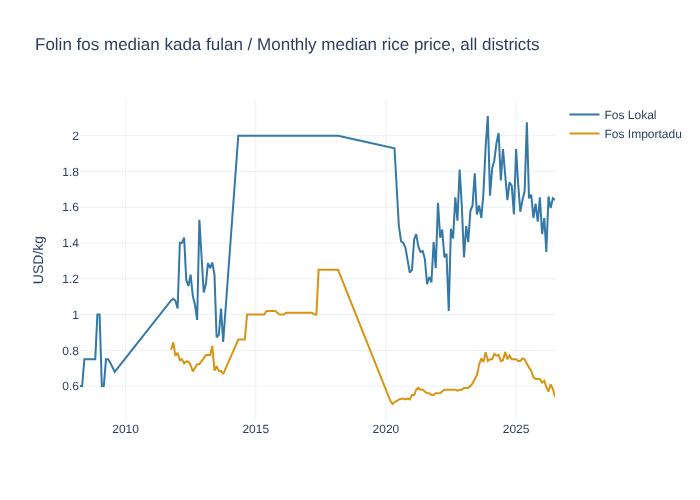

In [8]:
trend = (df.groupby([df["data"].dt.to_period("M").dt.to_timestamp(), "produto"])["folin_kg_usd"]
         .median().reset_index())
fig = px.line(trend, x="data", y="folin_kg_usd", color="produto", color_discrete_map=COR,
              labels={"folin_kg_usd": "USD/kg", "data": "", "produto": ""},
              title="Folin fos median kada fulan / Monthly median rice price, all districts")
save(fig, "eda_01_trend_rice").show()

In [9]:
# Yearly median since 2020
yearly = dfr.groupby([dfr["data"].dt.year, "produto"])["folin_kg_usd"].median().unstack().round(2)
yearly

produto,Fos Importadu,Fos Lokal
data,,
2020,0.52,1.43
2021,0.56,1.30
2022,0.58,1.44
2023,0.65,1.58
2024,0.76,1.75
2025,0.73,1.64
2026,0.60,1.54


## 4. Distribution by district / Distribuisaun kada munisípiu

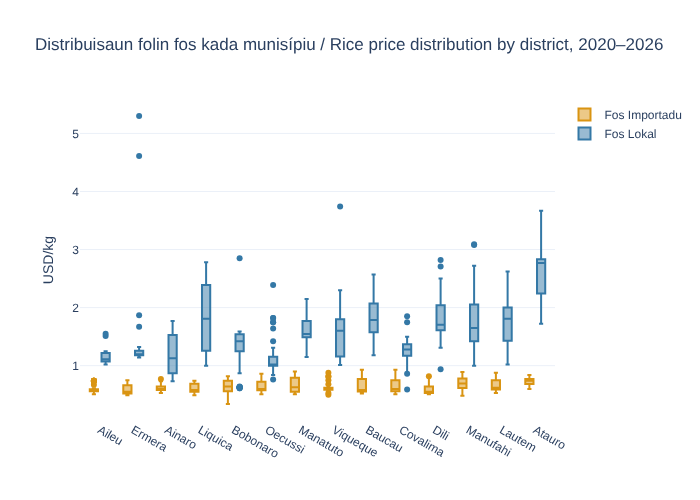

In [10]:
order = dfr.groupby("lokalizasaun")["folin_kg_usd"].median().sort_values().index.tolist()
fig = px.box(dfr, x="lokalizasaun", y="folin_kg_usd", color="produto", color_discrete_map=COR,
             category_orders={"lokalizasaun": order}, points="outliers",
             labels={"folin_kg_usd": "USD/kg", "lokalizasaun": "", "produto": ""},
             title="Distribuisaun folin fos kada munisípiu / Rice price distribution by district, 2020–2026")
save(fig, "eda_02_boxplot_district", height=550).show()

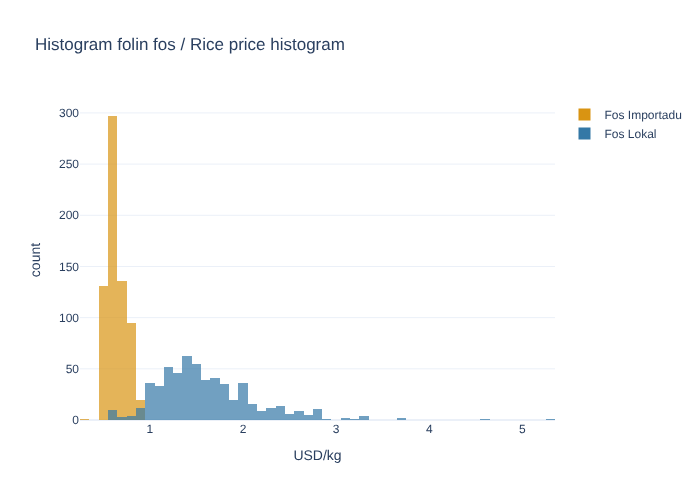

In [11]:
fig = px.histogram(dfr, x="folin_kg_usd", color="produto", color_discrete_map=COR, nbins=50,
                   barmode="overlay", opacity=0.7, labels={"folin_kg_usd": "USD/kg", "produto": ""},
                   title="Histogram folin fos / Rice price histogram")
save(fig, "eda_03_histogram").show()

## 5. Dili vs other districts / Dili kompara ho munisípiu seluk

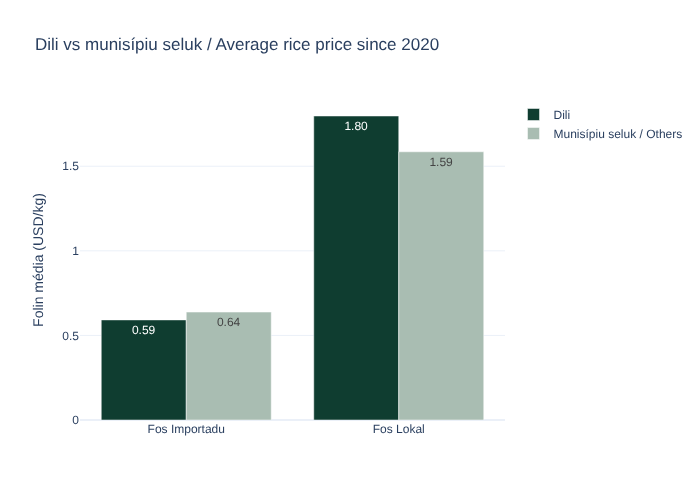

area,Dili,Munisípiu seluk / Others,diferensa_pct
produto,,,
Fos Importadu,0.59,0.64,-7.28
Fos Lokal,1.80,1.59,13.34


In [12]:
cmp = (dfr.assign(area=np.where(dfr["lokalizasaun"] == "Dili", "Dili", "Munisípiu seluk / Others"))
       .groupby(["produto", "area"])["folin_kg_usd"].mean().reset_index())
fig = px.bar(cmp, x="produto", y="folin_kg_usd", color="area", barmode="group", text_auto=".2f",
             color_discrete_sequence=["#0F3D30", "#A9BDB2"],
             labels={"folin_kg_usd": "Folin média (USD/kg)", "produto": "", "area": ""},
             title="Dili vs munisípiu seluk / Average rice price since 2020")
save(fig, "eda_04_dili_vs_districts").show()
cmp.pivot(index="produto", columns="area", values="folin_kg_usd").assign(
    diferensa_pct=lambda x: 100 * (x["Dili"] / x["Munisípiu seluk / Others"] - 1)).round(2)

## 6. Correlation local vs imported / Korrelasaun fos lokal no importadu

Correlation of monthly price LEVELS : 0.67
Correlation of monthly % CHANGES    : 0.04


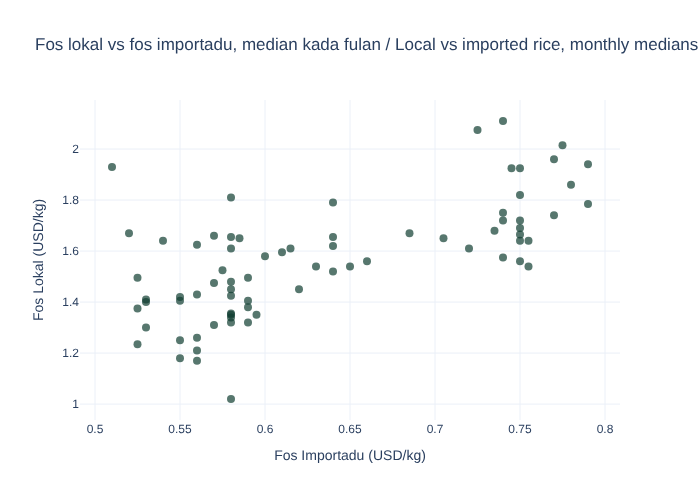

In [13]:
wide = trend[trend["data"] >= "2020-05-01"].pivot(index="data", columns="produto", values="folin_kg_usd")
print("Correlation of monthly price LEVELS :", round(wide.corr().iloc[0, 1], 2))
print("Correlation of monthly % CHANGES    :", round(wide.pct_change().corr().iloc[0, 1], 2))
fig = px.scatter(wide.reset_index(), x="Fos Importadu", y="Fos Lokal", trendline=None,
                 labels={"Fos Importadu": "Fos Importadu (USD/kg)", "Fos Lokal": "Fos Lokal (USD/kg)"},
                 title="Fos lokal vs fos importadu, median kada fulan / Local vs imported rice, monthly medians")
fig.update_traces(marker=dict(size=8, color="#0F3D30", opacity=0.7))
save(fig, "eda_05_corr_local_imported").show()

## 7. Seasonality / Sazonalidade

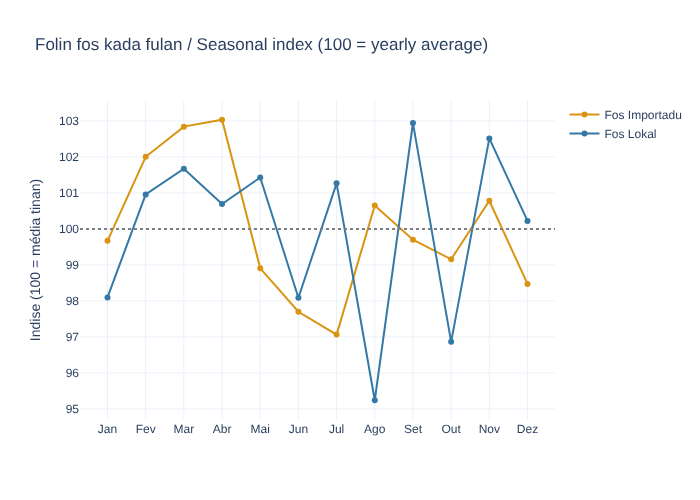

fulan,1,2,3,4,5,6,7,8,9,10,11,12
produto,,,,,,,,,,,,
Fos Importadu,99.7,102.0,102.8,103.0,98.9,97.7,97.1,100.7,99.7,99.2,100.8,98.5
Fos Lokal,98.1,101.0,101.7,100.7,101.4,98.1,101.3,95.2,102.9,96.9,102.5,100.2


In [14]:
season = dfr.groupby(["produto", "fulan"])["folin_kg_usd"].mean().reset_index()
season["indise"] = 100 * season["folin_kg_usd"] / season.groupby("produto")["folin_kg_usd"].transform("mean")
fig = px.line(season, x="fulan", y="indise", color="produto", markers=True, color_discrete_map=COR,
              labels={"indise": "Indise (100 = média tinan)", "fulan": "", "produto": ""},
              title="Folin fos kada fulan / Seasonal index (100 = yearly average)")
fig.add_hline(y=100, line_dash="dot", line_color="gray")
fig.update_xaxes(tickvals=list(range(1, 13)),
                 ticktext=["Jan","Fev","Mar","Abr","Mai","Jun","Jul","Ago","Set","Out","Nov","Dez"])
save(fig, "eda_06_seasonality").show()
season.pivot(index="produto", columns="fulan", values="indise").round(1)

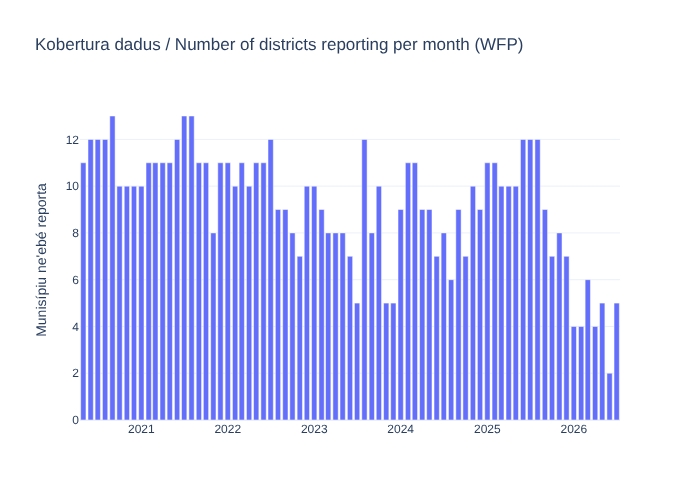

In [15]:
# Coverage: how many districts report each month? (fewer = less reliable months)
cov = dfr.groupby(dfr["data"].dt.to_period("M").dt.to_timestamp())["lokalizasaun"].nunique().reset_index()
fig = px.bar(cov, x="data", y="lokalizasaun", labels={"lokalizasaun": "Munisípiu ne'ebé reporta", "data": ""},
             title="Kobertura dadus / Number of districts reporting per month (WFP)")
save(fig, "eda_07_coverage").show()

## 8. Insights / Konkluzaun EDA

*(WFP data May 2020 → July 2026; re-run the notebook after each update)*

1. **Local rice costs about 2.5 times imported rice.** Since 2020 Fos Lokal averages **1.61 USD/kg** and Fos Importadu **0.63 USD/kg**. Most households in Timor-Leste therefore depend on imported rice.
2. **Fos Lokal is much more volatile.** Its coefficient of variation is 34% against 16% for imported rice, and its month-to-month changes have a standard deviation of 27% against 8%. Local supply depends on the harvest and on few traders; imported rice comes through a steadier supply chain.
3. **Imported rice followed a world shock.** The median imported price rose from about 0.59 USD/kg (early 2023) to 0.76 USD/kg (2024), after India restricted rice exports in mid-2023, and has fallen back to about 0.54 USD/kg in mid-2026. Local rice also peaked in 2024 (yearly median 1.75 USD/kg).
4. **Dili pays more for local rice but less for imported rice.** Fos Lokal is 13% more expensive in Dili than in the other districts, while Fos Importadu is 7% cheaper in Dili, close to the port where imported rice arrives.
5. **Ataúro is the most expensive district** for both types (Fos Lokal 2.66, Fos Importadu 0.73 USD/kg), because everything comes by boat; Oecussi and Aileu are the cheapest for local rice.
6. **Price levels move together, monthly changes do not.** Monthly medians of local and imported rice correlate at r = 0.67 (both rose in 2023–24), but their month-to-month changes are uncorrelated (r ≈ 0.04), so each rice type needs its own model.
7. **Seasonality is weak.** Imported rice is 2–3% above its yearly average in February–April and about 3% below in June–July; local rice has no regular pattern (largest dip −5% in August). Rice prices are driven more by supply shocks than by the calendar.
8. **Data coverage is falling.** In 2026 only 2–6 districts report rice prices each month; daily Taibesi prices from the Google Sheet would make the monitoring more reliable.